# Etude de l'early dropout sur un problème de régression

Le dataset utilisé est California Housing, la variable à prédire est le prix médian d'un groupe de maison en Californie exprimé en centaine de milliers de dollar. Nous avons 8 variables explicatives qui donnent des informations sur le groupe de maisons.

Comme fonction de loss nous utilisons le MSE, comme métrique de performance d'un modèle nous utilisons le R2, l'optimizer utilisé est Adam

Etapes du travail:

1. **Calibration** de la largeur et du nombre d'epochs avec le critère du papier (delta entre dropout standard et sans dropout) pour trouver un régime de sous-apprentissage.
2. **Grille early dropout** (fractions de `EARLY_GRID`) sur 5 graines, avec intervalles de confiance à 95 %.

Ce qui change par rapport à la classification :
- fonction d'entraînement `entrainer_regression` (loss MSE, métrique **R²** à la place de l'accuracy) ;
- les cibles sont standardisées avec les stats du train, donc la MSE est en unités d'écart-type² et R² ≈ 1 − MSE ;

In [ ]:
import os, glob
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from config import BATCH, P, EARLY_GRID
from models import mlp
from train import entrainer_regression

In [4]:
X, y = fetch_california_housing(return_X_y=True)      # télécharge au premier appel (Internet requis), puis cache
print(X.shape, y.shape)                                # (20640, 8) (20640,)

# 60 % train / 20 % val / 20 % test (splits fixes)
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, random_state=1)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=1)

# normalisation avec les stats du train uniquement (en numpy, avant la conversion en tenseurs)
sx = StandardScaler().fit(X_train)
X_train, X_val, X_test = sx.transform(X_train), sx.transform(X_val), sx.transform(X_test)

# cibles standardisées aussi : MSE en unités d'écart-type², R² ≈ 1 - MSE
y_mu, y_sd = y_train.mean(), y_train.std()
y_train, y_val, y_test = [(a - y_mu) / y_sd for a in (y_train, y_val, y_test)]

to_t = lambda a: torch.tensor(a, dtype=torch.float32)
data = dict(Xtr=to_t(X_train), ytr=to_t(y_train), Xva=to_t(X_val), yva=to_t(y_val),
            Xte=to_t(X_test), yte=to_t(y_test))
print(data["Xtr"].shape, data["Xva"].shape, data["Xte"].shape)

(20640, 8) (20640,)
torch.Size([12384, 8]) torch.Size([4128, 8]) torch.Size([4128, 8])


## Paramètres propres à ce cadre

`EARLY_GRID` (dans `config.py`) donne la durée de la phase de dropout en fraction de `EPOCHS` :
0 = pas de dropout, 1 = dropout standard (tout l'entraînement), entre les deux = early dropout.

In [5]:
CADRE = "mlp_california"
OUT = "resultats"
os.makedirs(OUT, exist_ok=True)

# Calibration du nombre d'epochs et de la largeur du modèle
On entraîne le même modèle sans dropout puis avec dropout standard, et on regarde la différence de R² de validation (le delta, en points).
Le dropout standard retire de la capacité au modèle.

- Si le modèle surapprend, retirer de la capacité l'aide : delta > 0.
- Si le modèle sous-apprend, il manque déjà de capacité, et en retirer encore le pénalise : delta < 0.

In [6]:
CALIB_WIDTHS = [8, 16, 32, 64]
CALIB_EPOCHS = [10, 20, 50, 100]
CALIB_GRID = [0, 1]          # 0 = sans dropout, 1 = dropout standard
CALIB_SEEDS = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

for WIDTH in CALIB_WIDTHS:
    for EPOCHS in CALIB_EPOCHS:
        for frac in CALIB_GRID:
            for seed in CALIB_SEEDS:
                fichier = f"{OUT}/{CADRE}_w{WIDTH}_e{EPOCHS}_frac{frac}_s{seed}.csv"
                if os.path.exists(fichier):
                    continue
                torch.manual_seed(seed)
                model, opt = mlp(8, 1, couche_cache=WIDTH)        # 8 features, 1 sortie
                hist = entrainer_regression(model, opt, data, EPOCHS, t_early=round(frac * EPOCHS),
                                            p=P, batch=BATCH)
                hist.assign(cadre=CADRE, width=WIDTH, epochs=EPOCHS, frac=frac, seed=seed).to_csv(fichier, index=False)
                print(f"w{WIDTH} e{EPOCHS} frac {frac} seed {seed}  val R² {hist.val_r2.iloc[-1]:.4f}")

In [7]:
cal = pd.concat(pd.read_csv(f) for f in glob.glob(f"{OUT}/{CADRE}_w*_e*_frac*_s*.csv"))
cal = cal[cal.width.isin(CALIB_WIDTHS) & cal.epochs.isin(CALIB_EPOCHS) & cal.frac.isin(CALIB_GRID) & cal.seed.isin(CALIB_SEEDS)]

# valeur finale = moyenne des 5 dernières epochs de chaque run
fin = (cal[cal.epoch >= cal.epochs - 5]
       .groupby(["width", "epochs", "frac", "seed"])[["train_loss", "val_loss", "val_r2"]].mean()
       .reset_index())

t = fin.pivot_table(index=["width", "epochs", "seed"], columns="frac", values="val_r2")
t["delta"] = (t[1] - t[0]) * 100                         # standard dropout- aucun dropout, en points de R²

# remontée relative de la loss de validation sans dropout, sur la moyenne glissante (fenêtre de 5 epochs) :
# (dernière fenêtre - meilleure fenêtre) / meilleure fenêtre
# 0 = la val loss est encore à son minimum à la fin ; plus c'est grand, plus elle a remonté (début de surapprentissage)
rem = {}
for (w, e, s), d in cal[cal.frac == 0].groupby(["width", "epochs", "seed"]):
    sm = d.sort_values("epoch").val_loss.rolling(5).mean().dropna()
    rem[(w, e, s)] = (sm.iloc[-1] - sm.min()) / sm.min()
rem = pd.Series(rem)
rem.index.names = ["width", "epochs", "seed"]

tab = t.groupby(["width", "epochs"]).agg(
    r2_sans_dropout=(0, "mean"),
    r2_avec_dropout=(1, "mean"),
    delta_moy=("delta", "mean"),
    delta_min=("delta", "min"),
    delta_max=("delta", "max"),
)
tab["remontee_val_loss"] = rem.groupby(["width", "epochs"]).mean()
tab["sous_apprentissage"] = tab.delta_max <= 0        # aucun gain R2 sur chaque seed
tab["pas_de_surapprentissage"] = tab.remontee_val_loss < 0.03      # moins de 3 % de remontée
tab = tab.round(3)

À lire : une configuration est retenue comme sous-apprentissage si toutes les graines ont un delta ≤ 0.

On observe que le modèle de largeur 8 entraîné sur 10 epochs est celui qui perd le plus de capacité avec dropout. Le modèle est clairement limité par sa capacité: plus la largeur du modèle augmente plus le r2 augmente. 

On décide de comparer l'effet de l'early dropout sur les modèles: 
- width=8, epoch=50 
- width=8, epoch=100 
- width=16, epoch=20 
- width=16, epoch=50 
- width=32, epoch=50 
- width=32, epoch=100 
- width=64, epoch=20 
- width=64, epoch=50 

Ces modèles sont tous en régime de sous-apprentissage.


## Entraînement sur différentes valeurs d'early dropout: 5%, 10%, 20%, 30%, 50%.
(un CSV par run, les runs déjà faits sont sautés)

In [8]:
EPOCHS_LIST = [20, 50, 100]
SEEDS = [0, 1, 2, 3, 4]
EARLY_GRID = [0, 0.05, 0.1, 0.2, 0.3, 0.5, 1]

for E in EPOCHS_LIST:
    print(E, "epochs :", [round(frac * E) for frac in EARLY_GRID], "epochs de dropout")

20 epochs : [0, 1, 2, 4, 6, 10, 20] epochs de dropout
50 epochs : [0, 2, 5, 10, 15, 25, 50] epochs de dropout
100 epochs : [0, 5, 10, 20, 30, 50, 100] epochs de dropout


In [9]:
WIDTH = 8
EPOCHS_LIST = [50, 100]

for EPOCHS in EPOCHS_LIST:
    for frac in EARLY_GRID:
        for seed in SEEDS:
            fichier = f"{OUT}/{CADRE}_w{WIDTH}_e{EPOCHS}_frac{frac}_s{seed}.csv"
            if os.path.exists(fichier):
                continue
            torch.manual_seed(seed)
            model, opt = mlp(8, 1, couche_cache=WIDTH)
            hist = entrainer_regression(model, opt, data, EPOCHS, t_early=round(frac * EPOCHS),
                                        p=P, batch=BATCH)
            hist.assign(cadre=CADRE, width=WIDTH, epochs=EPOCHS, frac=frac, seed=seed).to_csv(fichier, index=False)
            print(f"e{EPOCHS} frac {frac:<4} seed {seed}  val R² {hist.val_r2.iloc[-1]:.4f}")

In [10]:
WIDTH = 16
EPOCHS_LIST = [20, 50]

for EPOCHS in EPOCHS_LIST:
    for frac in EARLY_GRID:
        for seed in SEEDS:
            fichier = f"{OUT}/{CADRE}_w{WIDTH}_e{EPOCHS}_frac{frac}_s{seed}.csv"
            if os.path.exists(fichier):
                continue
            torch.manual_seed(seed)
            model, opt = mlp(8, 1, couche_cache=WIDTH)
            hist = entrainer_regression(model, opt, data, EPOCHS, t_early=round(frac * EPOCHS),
                                        p=P, batch=BATCH)
            hist.assign(cadre=CADRE, width=WIDTH, epochs=EPOCHS, frac=frac, seed=seed).to_csv(fichier, index=False)
            print(f"e{EPOCHS} frac {frac:<4} seed {seed}  val R² {hist.val_r2.iloc[-1]:.4f}")

In [11]:
WIDTH = 32
EPOCHS_LIST = [50, 100]

for EPOCHS in EPOCHS_LIST:
    for frac in EARLY_GRID:
        for seed in SEEDS:
            fichier = f"{OUT}/{CADRE}_w{WIDTH}_e{EPOCHS}_frac{frac}_s{seed}.csv"
            if os.path.exists(fichier):
                continue
            torch.manual_seed(seed)
            model, opt = mlp(8, 1, couche_cache=WIDTH)
            hist = entrainer_regression(model, opt, data, EPOCHS, t_early=round(frac * EPOCHS),
                                        p=P, batch=BATCH)
            hist.assign(cadre=CADRE, width=WIDTH, epochs=EPOCHS, frac=frac, seed=seed).to_csv(fichier, index=False)
            print(f"e{EPOCHS} frac {frac:<4} seed {seed}  val R² {hist.val_r2.iloc[-1]:.4f}")

In [12]:
WIDTH = 64
EPOCHS_LIST = [20, 50]

for EPOCHS in EPOCHS_LIST:
    for frac in EARLY_GRID:
        for seed in SEEDS:
            fichier = f"{OUT}/{CADRE}_w{WIDTH}_e{EPOCHS}_frac{frac}_s{seed}.csv"
            if os.path.exists(fichier):
                continue
            torch.manual_seed(seed)
            model, opt = mlp(8, 1, couche_cache=WIDTH)
            hist = entrainer_regression(model, opt, data, EPOCHS, t_early=round(frac * EPOCHS),
                                        p=P, batch=BATCH)
            hist.assign(cadre=CADRE, width=WIDTH, epochs=EPOCHS, frac=frac, seed=seed).to_csv(fichier, index=False)
            print(f"e{EPOCHS} frac {frac:<4} seed {seed}  val R² {hist.val_r2.iloc[-1]:.4f}")

## Analyse : relit tous les CSV de ce cadre

In [13]:
# Analyse appariée par largeur : chaque run est comparé au run sans dropout de la même graine.
ANALYSIS_EPOCHS = {
    8: [50, 100],
    16: [20, 50],
    32: [50, 100],
    64: [20, 50],
}
T95 = {2: 12.71, 3: 4.30, 4: 3.18, 5: 2.78}

comp_by_width = {}
tab_by_width = {}

for width, epochs_list in ANALYSIS_EPOCHS.items():
    comp_runs = []
    for E in epochs_list:
        fichiers = glob.glob(f"{OUT}/{CADRE}_w{width}_e{E}_frac*_s*.csv")
        if not fichiers:
            raise FileNotFoundError(f"Aucun CSV trouvé pour width={width}, epochs={E}")

        d = pd.concat((pd.read_csv(fp) for fp in fichiers), ignore_index=True)
        d = d[d.seed.isin(SEEDS) & d.frac.isin(EARLY_GRID)]
        fe = (d[d.epoch >= E - 5]
              .groupby(["frac", "seed"])[["train_loss", "val_r2", "test_r2"]].mean()
              .reset_index())

        base = fe[fe.frac == 0].set_index("seed")
        if not set(SEEDS).issubset(base.index):
            raise ValueError(f"Baseline sans dropout incomplète pour width={width}, epochs={E}")
        for col in ["train_loss", "val_r2", "test_r2"]:
            fe[f"d_{col}"] = fe[col] - fe.seed.map(base[col])
        fe["epochs"] = E
        comp_runs.append(fe)

    comp = pd.concat(comp_runs, ignore_index=True)
    comp_by_width[width] = comp

    def ic95(values):
        n = len(values)
        if n not in T95:
            raise ValueError(f"Il faut entre 2 et 5 graines pour calculer l'IC à 95 % (reçu {n})")
        return T95[n] * values.std() / n ** 0.5

    stats = comp.groupby(["epochs", "frac"]).agg(
        gain_val=("d_val_r2", lambda x: 100 * x.mean()),
        ic_val=("d_val_r2", lambda x: 100 * ic95(x)),
        gain_test=("d_test_r2", lambda x: 100 * x.mean()),
        ic_test=("d_test_r2", lambda x: 100 * ic95(x)),
        d_train_loss=("d_train_loss", "mean"),
        ic_train_loss=("d_train_loss", ic95),
    )
    tab_by_width[width] = stats

Les cellules suivantes affichent les gains de R² en validation et en test (R2 early dropout - R2 sans dropout), ainsi que l'écart de loss d'entraînement par rapport au modèle sans dropout (train loss early dropout - train loss sans dropout). Les barres représentent les intervalles de confiance à 95 % sur les graines.

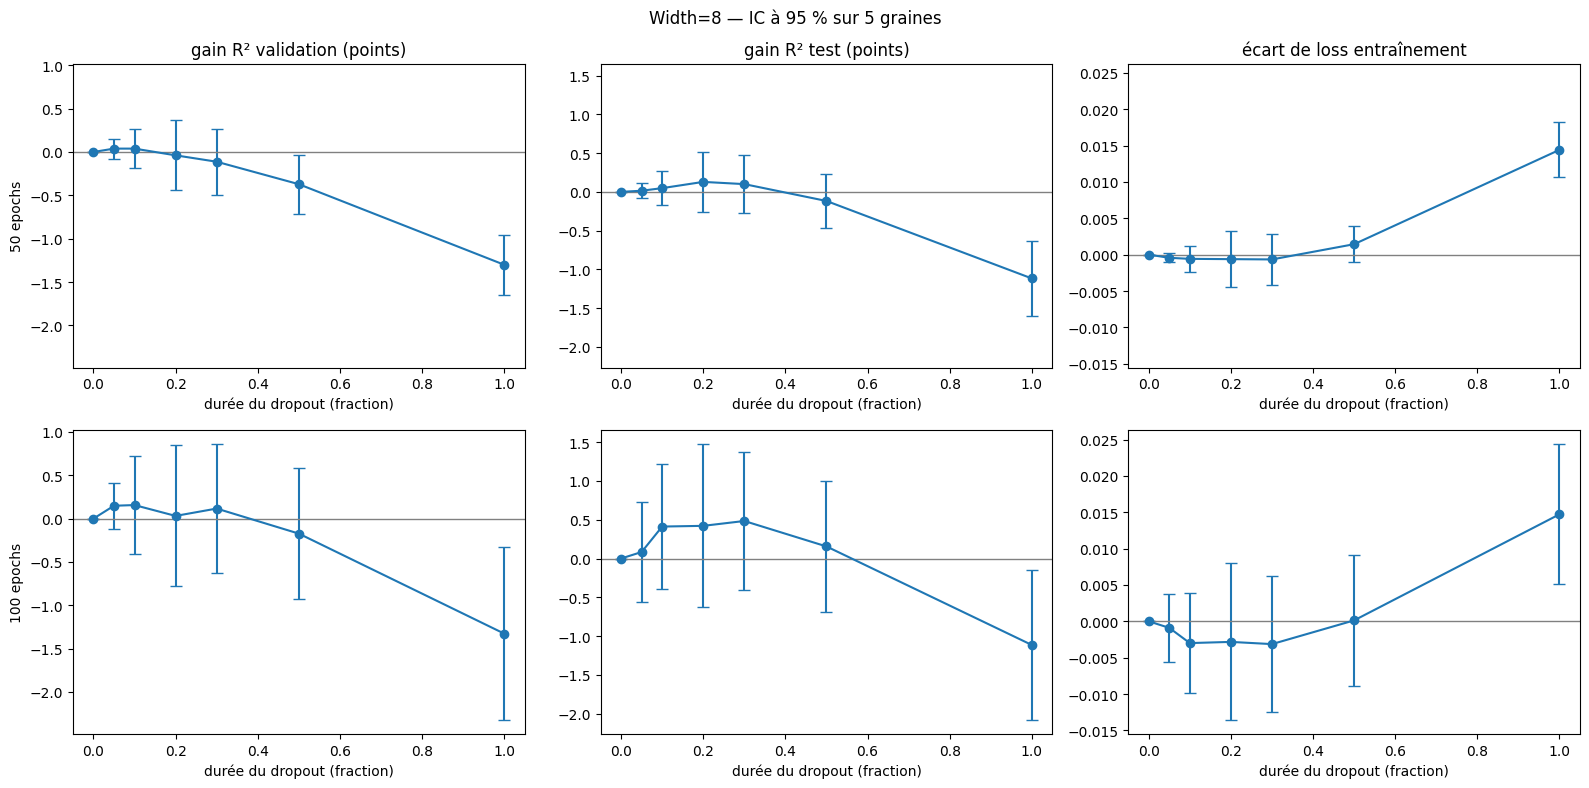

In [14]:
# Graphiques pour width=8
W = 8
stats = tab_by_width[W]
fig, axes = plt.subplots(len(ANALYSIS_EPOCHS[W]), 3, figsize=(16, 4 * len(ANALYSIS_EPOCHS[W])), sharey="col", squeeze=False)
for r, E in enumerate(ANALYSIS_EPOCHS[W]):
    t = stats.xs(E, level="epochs")
    axes[r, 0].errorbar(t.index, t.gain_val, yerr=t.ic_val, marker="o", capsize=4)
    axes[r, 1].errorbar(t.index, t.gain_test, yerr=t.ic_test, marker="o", capsize=4)
    axes[r, 2].errorbar(t.index, t.d_train_loss, yerr=t.ic_train_loss, marker="o", capsize=4)
    axes[r, 0].set_ylabel(f"{E} epochs")
    for ax in axes[r]:
        ax.axhline(0, color="gray", lw=1)
        ax.set_xlabel("durée du dropout (fraction)")
axes[0, 0].set_title("gain R² validation (points)")
axes[0, 1].set_title("gain R² test (points)")
axes[0, 2].set_title("écart de loss entraînement")
fig.suptitle(f"Width={W} — IC à 95 % sur {len(SEEDS)} graines")
fig.tight_layout()
plt.show()

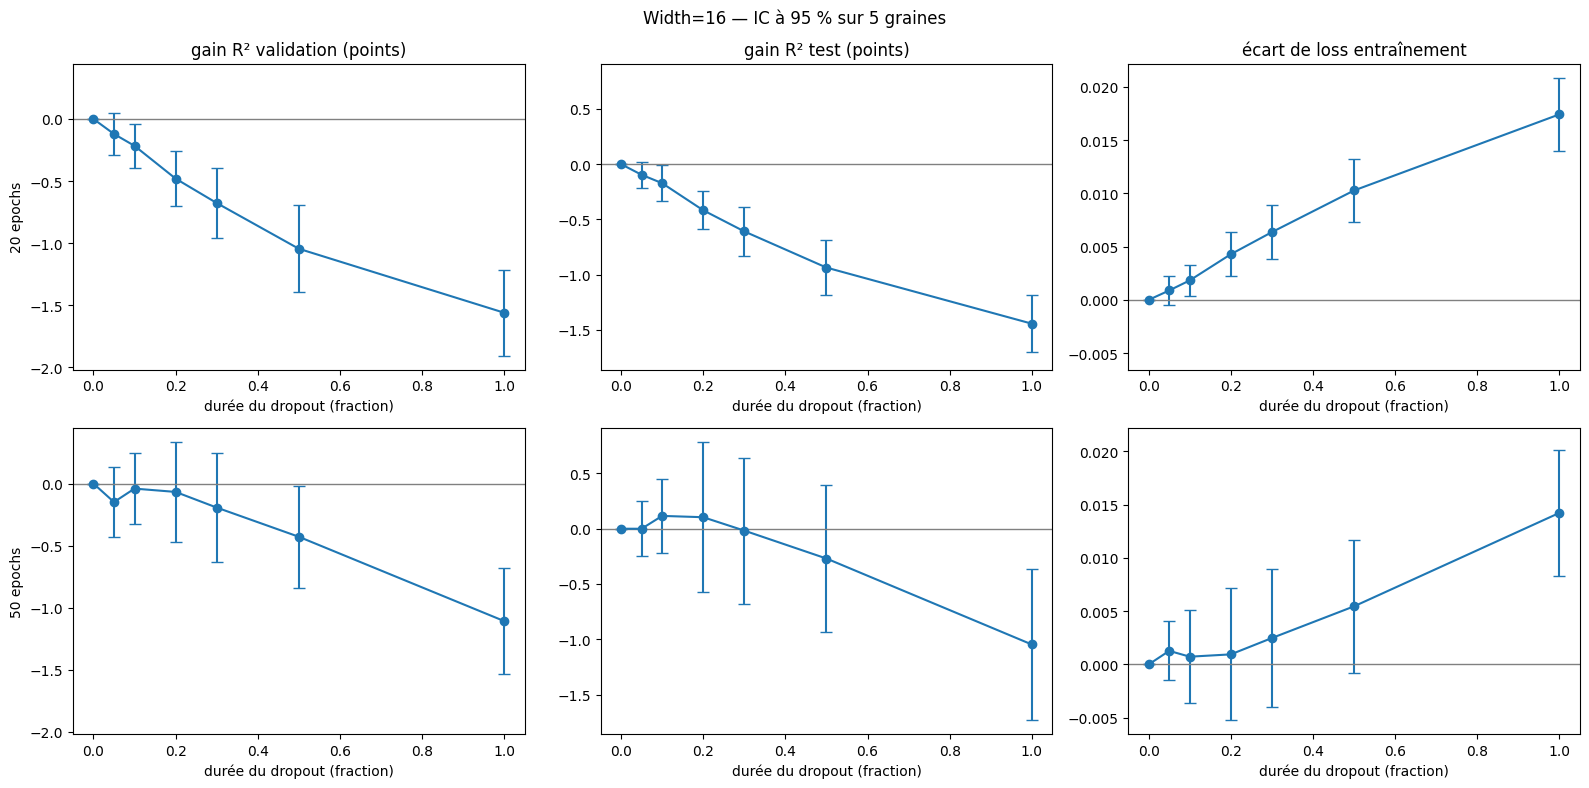

In [15]:
# Graphiques pour width=16
W = 16
stats = tab_by_width[W]
fig, axes = plt.subplots(len(ANALYSIS_EPOCHS[W]), 3, figsize=(16, 4 * len(ANALYSIS_EPOCHS[W])), sharey="col", squeeze=False)
for r, E in enumerate(ANALYSIS_EPOCHS[W]):
    t = stats.xs(E, level="epochs")
    axes[r, 0].errorbar(t.index, t.gain_val, yerr=t.ic_val, marker="o", capsize=4)
    axes[r, 1].errorbar(t.index, t.gain_test, yerr=t.ic_test, marker="o", capsize=4)
    axes[r, 2].errorbar(t.index, t.d_train_loss, yerr=t.ic_train_loss, marker="o", capsize=4)
    axes[r, 0].set_ylabel(f"{E} epochs")
    for ax in axes[r]:
        ax.axhline(0, color="gray", lw=1)
        ax.set_xlabel("durée du dropout (fraction)")
axes[0, 0].set_title("gain R² validation (points)")
axes[0, 1].set_title("gain R² test (points)")
axes[0, 2].set_title("écart de loss entraînement")
fig.suptitle(f"Width={W} — IC à 95 % sur {len(SEEDS)} graines")
fig.tight_layout()
plt.show()

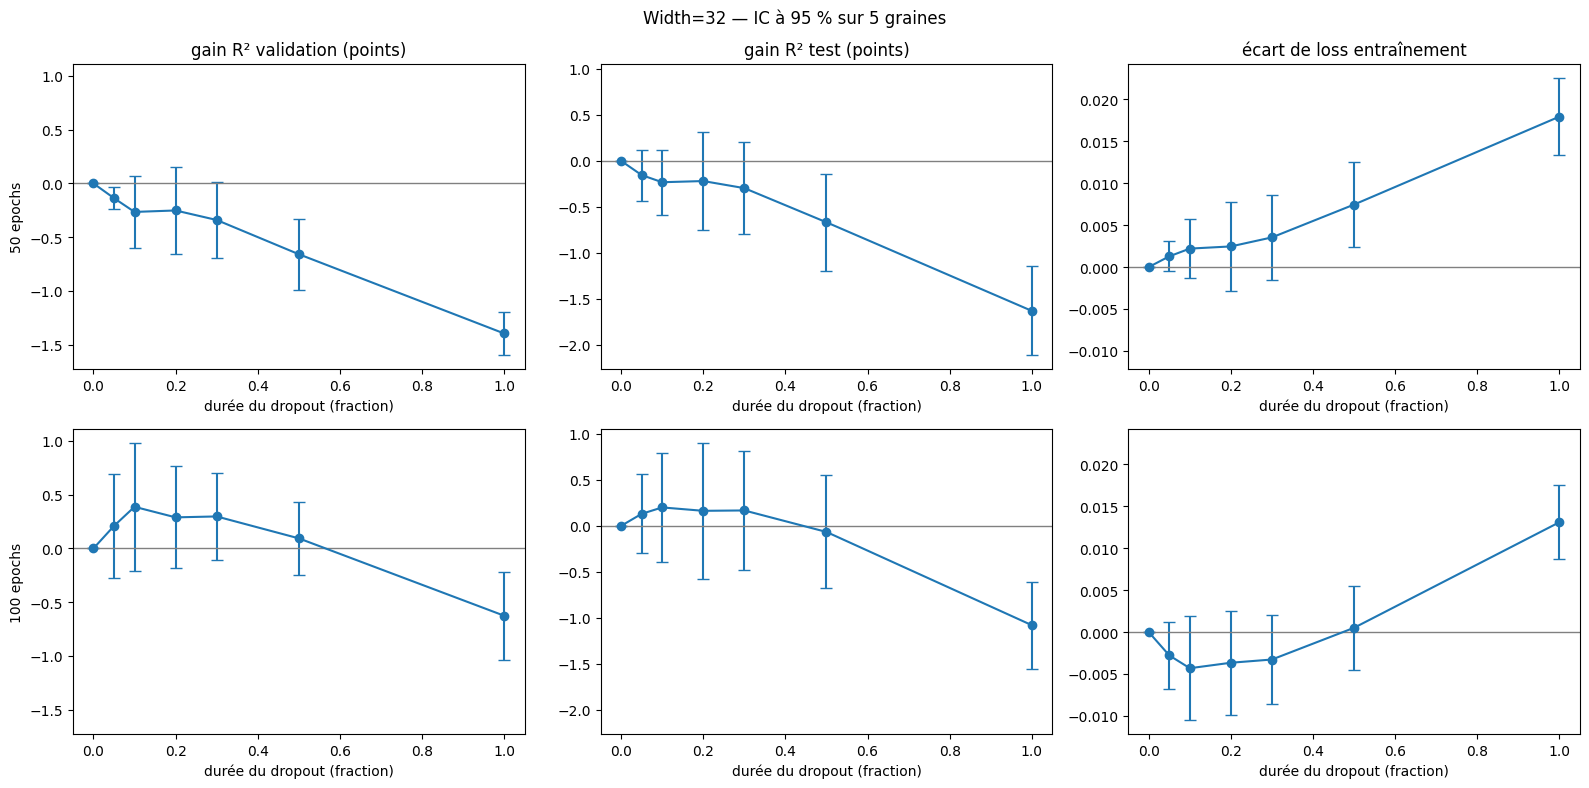

In [16]:
# Graphiques pour width=32
W = 32
stats = tab_by_width[W]
fig, axes = plt.subplots(len(ANALYSIS_EPOCHS[W]), 3, figsize=(16, 4 * len(ANALYSIS_EPOCHS[W])), sharey="col", squeeze=False)
for r, E in enumerate(ANALYSIS_EPOCHS[W]):
    t = stats.xs(E, level="epochs")
    axes[r, 0].errorbar(t.index, t.gain_val, yerr=t.ic_val, marker="o", capsize=4)
    axes[r, 1].errorbar(t.index, t.gain_test, yerr=t.ic_test, marker="o", capsize=4)
    axes[r, 2].errorbar(t.index, t.d_train_loss, yerr=t.ic_train_loss, marker="o", capsize=4)
    axes[r, 0].set_ylabel(f"{E} epochs")
    for ax in axes[r]:
        ax.axhline(0, color="gray", lw=1)
        ax.set_xlabel("durée du dropout (fraction)")
axes[0, 0].set_title("gain R² validation (points)")
axes[0, 1].set_title("gain R² test (points)")
axes[0, 2].set_title("écart de loss entraînement")
fig.suptitle(f"Width={W} — IC à 95 % sur {len(SEEDS)} graines")
fig.tight_layout()
plt.show()

Sur ce modèle, dans le cas avec 50 epochs, nous voyons que l'early dropout fait augmenter la train loss comparé au modèle sans dropout. Plus l'early est longtemps plus la train loss augmente comparé au modèle sans dropout.
Même chose, pour le R2 val et test, l'early dropout fais perdre de la capacité au modèle. En effet, le R2 sur la val et le test avec early-dropout est inférieur au R2 sans dropout. Cet effet s'accentue plus la fraction d'early est grande.

Dans le cas avec 100 epochs, les trois premiers régimes: 10%, 20%, et 30% ont en moyenne une train loss plus petite, mais on n'est pas totalement satisfait du résultat car l'intervalle de confiance à 95% contient 0: on ne peut pas dire avec une probabilité de 95% que l'early dropout diminue la train loss. Même chose pour le R2 val et test.

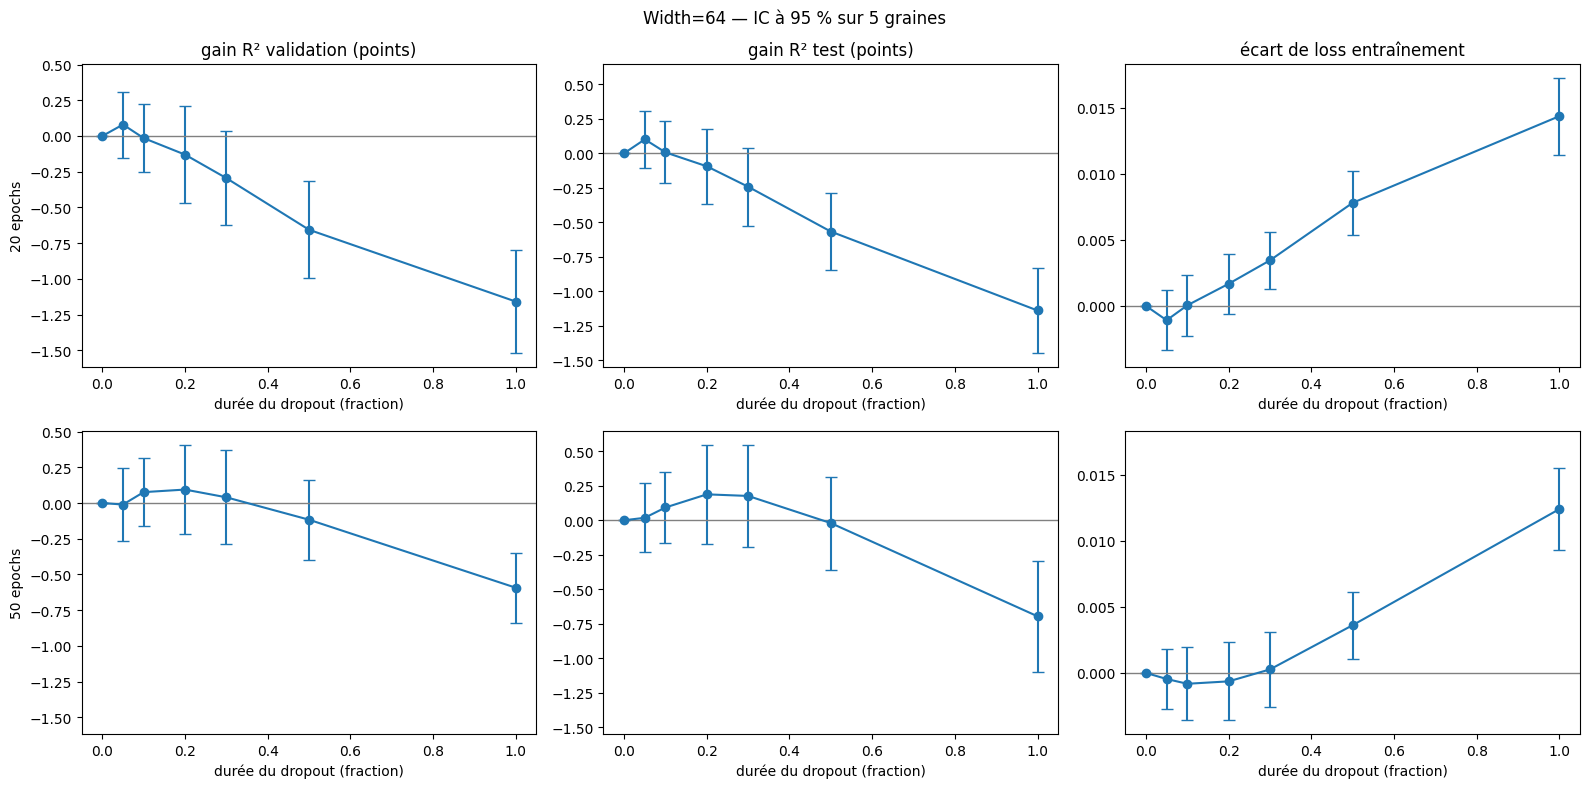

In [17]:
# Graphiques pour width=64
W = 64
stats = tab_by_width[W]
fig, axes = plt.subplots(len(ANALYSIS_EPOCHS[W]), 3, figsize=(16, 4 * len(ANALYSIS_EPOCHS[W])), sharey="col", squeeze=False)
for r, E in enumerate(ANALYSIS_EPOCHS[W]):
    t = stats.xs(E, level="epochs")
    axes[r, 0].errorbar(t.index, t.gain_val, yerr=t.ic_val, marker="o", capsize=4)
    axes[r, 1].errorbar(t.index, t.gain_test, yerr=t.ic_test, marker="o", capsize=4)
    axes[r, 2].errorbar(t.index, t.d_train_loss, yerr=t.ic_train_loss, marker="o", capsize=4)
    axes[r, 0].set_ylabel(f"{E} epochs")
    for ax in axes[r]:
        ax.axhline(0, color="gray", lw=1)
        ax.set_xlabel("durée du dropout (fraction)")
axes[0, 0].set_title("gain R² validation (points)")
axes[0, 1].set_title("gain R² test (points)")
axes[0, 2].set_title("écart de loss entraînement")
fig.suptitle(f"Width={W} — IC à 95 % sur {len(SEEDS)} graines")
fig.tight_layout()
plt.show()

## Conclusion sur le MLP / California Housing

Sur tous les modèles choisis nous n'avons pas trouvé de cas où avec une probabilité de 95% l'early dropout améliore soit la train loss ou le R2 en val ou test. Néanmoins, nous avons des cas où sur la moyenne des 5 seeds le R2 est plus élevé en test et en val et que la train loss est plus petite. Par exemple, width=32, epoch=100.

On se pose maintenant le question de l'effet du batch_size sur l'early dropout. On sait que plus le batch_size est petit, plus il y a d'itérations (les paramètres sont mis à jours plus de fois). Dans le papier on parle en pourcentage du nombre d'epochs pour l'early dropout, mais ce qui compte réellement est le nombre d'itérations, autrement dit le batch_size associé au pourcentage de nombre d'epochs 